In [ ]:
%matplotlib inline
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("charts", exist_ok=True)

MON = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
SEASONS = ["Winter", "Summer", "Monsoon", "Post-monsoon"]
SEASON_COL = {"Winter":"#4c78a8", "Summer":"#f58518", "Monsoon":"#54a24b", "Post-monsoon":"#b279a2"}
SEASON_MAP = {12:"Winter",1:"Winter",2:"Winter",3:"Summer",4:"Summer",5:"Summer",6:"Summer",
              7:"Monsoon",8:"Monsoon",9:"Monsoon",10:"Post-monsoon",11:"Post-monsoon"}
CATS = [(50,"Good","#2e7d32"), (100,"Satisfactory","#9ccc65"), (200,"Moderate","#fdd835"),
        (300,"Poor","#fb8c00"), (400,"Very Poor","#e53935"), (500,"Severe","#7b1113")]
CAT_L = [c[1] for c in CATS]
CAT_C = [c[2] for c in CATS]

def show(fig, name, title=None):
    """tidy the figure, save it as PNG, and DISPLAY it in the notebook"""
    if title:
        fig.suptitle(title, fontsize=14, fontweight="bold", y=1.0)
    fig.tight_layout()
    fig.savefig(f"charts/{name}.png", dpi=110, bbox_inches="tight")
    plt.show()

print("Cell 1 done: libraries loaded")

Cell 1 done: libraries loaded


In [ ]:
import glob
found = glob.glob("delhi-weather-aqi-2025.csv")
if found:
    CSV = found[0]
else:
    from google.colab import files
    uploaded = files.upload()
    CSV = list(uploaded.keys())[0]
print("Using file:", CSV)

df = pd.read_csv(CSV)
df["datetime"] = pd.to_datetime(df["date_ist"] + " " + df["time_ist"], format="%d/%m/%Y %H:%M")
print(df.shape)
df.head()

Saving delhi-weather-aqi-2025.csv to delhi-weather-aqi-2025 (1).csv
Using file: delhi-weather-aqi-2025 (1).csv
(52560, 17)


,date_ist,time_ist,location,lat,lon,temp_c,humidity,pressure_mb,windspeed_kph,condition_text,description,aqi_index,pm2_5,pm10,co,no2,datetime
0,01/01/2025,0:00,Anand Vihar,28.6469,77.316,8.1,100,995.4,2.9,Mainly clear,WMO Code 1,197,185.8,188.6,1907,56.7,2025-01-01 00:00:00
1,01/01/2025,1:00,Anand Vihar,28.6469,77.316,7.7,100,994.7,3.2,Overcast,WMO Code 3,198,174.6,177.4,1669,44.8,2025-01-01 01:00:00
2,01/01/2025,2:00,Anand Vihar,28.6469,77.316,7.5,100,994.3,4.5,Overcast,WMO Code 3,199,164.4,166.7,1493,34.6,2025-01-01 02:00:00
3,01/01/2025,3:00,Anand Vihar,28.6469,77.316,7.8,99,994.1,6.0,Overcast,WMO Code 3,200,156.5,158.8,1401,26.7,2025-01-01 03:00:00
4,01/01/2025,4:00,Anand Vihar,28.6469,77.316,7.3,100,993.8,6.8,Overcast,WMO Code 3,200,149.5,151.8,1372,20.6,2025-01-01 04:00:00


In [ ]:
num = ["temp_c","humidity","pressure_mb","windspeed_kph","pm2_5","pm10","no2","co"]
lab = {"temp_c":"Temperature (C)", "humidity":"Humidity (%)", "pressure_mb":"Pressure (mb)",
       "windspeed_kph":"Wind (km/h)", "pm2_5":"PM2.5 (ug/m3)", "pm10":"PM10 (ug/m3)",
       "no2":"NO2 (ug/m3)", "co":"CO (ug/m3)"}

ZONES = {"Zone A": ["Anand Vihar", "Connaught Place", "Rohini"],
         "Zone B": ["Dwarka", "IGI Airport", "Okhla Phase III"]}

# zone-level hourly table
parts = []
for z, st in ZONES.items():
    g = df[df.location.isin(st)].groupby("datetime")[num].mean()
    g["zone"] = z
    parts.append(g)
hz = pd.concat(parts)
hz["month"] = hz.index.month
hz["hour"] = hz.index.hour
hz["season"] = hz.month.map(SEASON_MAP)

# city-wide hourly table
city = hz.groupby(level=0)[num].mean()
city["month"] = city.index.month
city["hour"] = city.index.hour
city["season"] = city.month.map(SEASON_MAP)

# daily tables
daily_z = hz.groupby("zone").resample("D")[num].mean().reset_index().rename(columns={"datetime": "date"})
daily_z["month"] = daily_z.date.dt.month
daily_z["season"] = daily_z.month.map(SEASON_MAP)

daily_c = city[num].resample("D").mean()
daily_c["month"] = daily_c.index.month
daily_c["season"] = daily_c.month.map(SEASON_MAP)

# official-style CPCB AQI from PM2.5
def pm25_aqi(c):
    return np.interp(c, [0,30,60,90,120,250,380], [0,50,100,200,300,400,500])

daily_z["aqi"] = pm25_aqi(daily_z.pm2_5)
daily_z["cat"] = pd.cut(daily_z.aqi, [-1] + [c[0] for c in CATS], labels=CAT_L)
daily_z["grap"] = pd.cut(daily_z.aqi, [-1,200,300,400,450,1e4],
                         labels=["None","Stage I","Stage II","Stage III","Stage IV"])

# temperature daily extremes (city average)
T = city.temp_c
dmax, dmin = T.resample("D").max(), T.resample("D").min()
wet = df.condition_text.str.contains("Rain|Drizzle")

print("hourly zone table:", hz.shape, "| daily zone table:", daily_z.shape)
daily_z.head()

hourly zone table: (17520, 12) | daily zone table: (730, 15)


,zone,date,temp_c,humidity,pressure_mb,windspeed_kph,pm2_5,pm10,no2,co,month,season,aqi,cat,grap
0,Zone A,2025-01-01,10.876389,89.652778,993.209722,5.543056,145.175000,147.837500,34.616667,1439.208333,1,Winter,319.365385,Very Poor,Stage II
1,Zone A,2025-01-02,12.163889,86.527778,992.438889,5.987500,145.370833,149.341667,33.241667,1591.388889,1,Winter,319.516026,Very Poor,Stage II
2,Zone A,2025-01-03,12.270833,89.611111,992.201389,3.545833,158.791667,168.179167,54.083333,2114.055556,1,Winter,329.839744,Very Poor,Stage II
3,Zone A,2025-01-04,12.798611,89.805556,990.127778,3.768056,166.491667,176.479167,76.295833,2618.027778,1,Winter,335.762821,Very Poor,Stage II
4,Zone A,2025-01-05,12.359722,89.625000,990.273611,5.904167,158.225000,163.804167,44.412500,1691.972222,1,Winter,329.403846,Very Poor,Stage II


In [ ]:
KPI = []
def kpi(group, name, value, unit=""):
    KPI.append((group, name, value if isinstance(value, str) else round(float(value), 2), unit))

# --- dataset and quality
kpi("Dataset","Rows",len(df)); kpi("Dataset","Columns",df.shape[1]-1)
kpi("Dataset","Stations",df.location.nunique()); kpi("Dataset","Hours covered",df.datetime.nunique(),"hours")
kpi("Dataset","Missing values",int(df.isna().sum().sum()))
kpi("Dataset","Duplicate rows (time+station)",int(df.duplicated(["datetime","location"]).sum()))
for z, st in ZONES.items():
    same = (df[df.location.isin(st)].pivot(index="datetime", columns="location", values="pm2_5").nunique(axis=1) == 1).all()
    kpi("Data quality", f"PM2.5 identical across stations in {z}", str(same))
kpi("Data quality","Original aqi_index above 500 (invalid)",(df.aqi_index > 500).mean()*100,"% of rows")
kpi("Data quality","Original aqi_index maximum",df.aqi_index.max())

# --- weather
kpi("Weather","Mean temperature",T.mean(),"C")
kpi("Weather","Hottest hour (city avg)",T.max(),"C"); kpi("Weather","Hottest hour time",str(T.idxmax()))
kpi("Weather","Coldest hour (city avg)",T.min(),"C"); kpi("Weather","Coldest hour time",str(T.idxmin()))
kpi("Weather","Days with max temp >= 40 C",(dmax >= 40).sum(),"days")
kpi("Weather","Days with max temp >= 35 C",(dmax >= 35).sum(),"days")
kpi("Weather","Days with min temp <= 10 C",(dmin <= 10).sum(),"days")
kpi("Weather","Average daily temperature range",(dmax - dmin).mean(),"C")
kpi("Weather","Mean relative humidity",city.humidity.mean(),"%")
kpi("Weather","Hours with humidity >= 90%",(city.humidity >= 90).mean()*100,"% of hours")
kpi("Weather","Mean pressure",city.pressure_mb.mean(),"mb")
kpi("Weather","Pressure range",city.pressure_mb.max()-city.pressure_mb.min(),"mb")
kpi("Weather","Mean wind speed",city.windspeed_kph.mean(),"km/h")
kpi("Weather","Max wind speed (hourly, any station)",df.windspeed_kph.max(),"km/h")
kpi("Weather","Calm hours (wind < 2 km/h)",(city.windspeed_kph < 2).mean()*100,"% of hours")
kpi("Weather","Rain/drizzle hours",wet.mean()*100,"% of station-hours")
rain_days = df[wet].assign(d=lambda x: x.datetime.dt.date).d.nunique()
kpi("Weather","Days with any rain/drizzle",rain_days,"days")
kpi("Weather","Fog hours (all stations)",(df.condition_text == "Fog").sum(),"station-hours")
kpi("Weather","Hottest day",str(dmax.idxmax().date())); kpi("Weather","Coldest day",str(dmin.idxmin().date()))

# --- pollution per zone
for z, g in daily_z.groupby("zone"):
    h = hz[hz.zone == z]
    kpi(f"Pollution {z}","Annual mean PM2.5",h.pm2_5.mean(),"ug/m3")
    kpi(f"Pollution {z}","Annual mean PM10",h.pm10.mean(),"ug/m3")
    kpi(f"Pollution {z}","Annual mean NO2",h.no2.mean(),"ug/m3")
    kpi(f"Pollution {z}","Annual mean CO",h.co.mean(),"ug/m3")
    kpi(f"Pollution {z}","Peak hourly PM2.5",h.pm2_5.max(),"ug/m3")
    kpi(f"Pollution {z}","Peak hourly PM2.5 time",str(h.pm2_5.idxmax()))
    kpi(f"Pollution {z}","Worst day (PM2.5)",str(g.loc[g.pm2_5.idxmax(),"date"].date()))
    kpi(f"Pollution {z}","Worst day mean PM2.5",g.pm2_5.max(),"ug/m3")
    kpi(f"Pollution {z}","Cleanest day mean PM2.5",g.pm2_5.min(),"ug/m3")
    kpi(f"Pollution {z}","Days above India limit (60)",(g.pm2_5 > 60).sum(),"days")
    kpi(f"Pollution {z}","Days above WHO guideline (15)",(g.pm2_5 > 15).sum(),"days")
    kpi(f"Pollution {z}","Days PM10 above India limit (100)",(g.pm10 > 100).sum(),"days")
    kpi(f"Pollution {z}","Annual PM2.5 vs India limit 40",h.pm2_5.mean()/40,"x limit")
    kpi(f"Pollution {z}","Annual PM2.5 vs WHO guideline 5",h.pm2_5.mean()/5,"x guideline")
    kpi(f"Pollution {z}","Mean PM2.5/PM10 ratio",(h.pm2_5/h.pm10).mean(),"")
    mm = g.groupby("month").pm2_5.mean()
    kpi(f"Pollution {z}","Worst month (PM2.5)",MON[mm.idxmax()-1])
    kpi(f"Pollution {z}","Cleanest month (PM2.5)",MON[mm.idxmin()-1])
    hh = h.groupby("hour").pm2_5.mean()
    kpi(f"Pollution {z}","Worst hour of day",f"{hh.idxmax()}:00 ({hh.max():.0f})")
    kpi(f"Pollution {z}","Cleanest hour of day",f"{hh.idxmin()}:00 ({hh.min():.0f})")
    for c in CAT_L: kpi(f"CPCB days {z}", c, (g.cat == c).sum(), "days")
    for s in ["Stage I","Stage II","Stage III","Stage IV"]: kpi(f"GRAP days (est.) {z}", s, (g.grap == s).sum(), "days")

# --- weather -> pollution links
kpi("Weather -> PM2.5","Spearman: wind vs PM2.5 (hourly)",stats.spearmanr(hz.windspeed_kph, hz.pm2_5)[0])
kpi("Weather -> PM2.5","Spearman: humidity vs PM2.5 (hourly)",stats.spearmanr(hz.humidity, hz.pm2_5)[0])
kpi("Weather -> PM2.5","Spearman: temperature vs PM2.5 (hourly)",stats.spearmanr(hz.temp_c, hz.pm2_5)[0])
kpi("Weather -> PM2.5","Mean PM2.5 in rain/drizzle hours",df[wet].pm2_5.mean(),"ug/m3")
kpi("Weather -> PM2.5","Mean PM2.5 in dry hours",df[~wet].pm2_5.mean(),"ug/m3")
kpi("Weather -> PM2.5","Mean PM2.5 in fog hours",df[df.condition_text == "Fog"].pm2_5.mean(),"ug/m3")

kdf = pd.DataFrame(KPI, columns=["Group","Parameter","Value","Unit"])
kdf.to_csv("key_parameters.csv", index=False)
print(len(kdf), "parameters recorded")
pd.set_option("display.max_rows", 200)
display(kdf)

95 parameters recorded


,Group,Parameter,Value,Unit
0,Dataset,Rows,52560.0,
1,Dataset,Columns,16.0,
2,Dataset,Stations,6.0,
3,Dataset,Hours covered,8760.0,hours
4,Dataset,Missing values,0.0,
5,Dataset,Duplicate rows (time+station),0.0,
6,Data quality,PM2.5 identical across stations in Zone A,True,
7,Data quality,PM2.5 identical across stations in Zone B,True,
8,Data quality,Original aqi_index above 500 (invalid),13.13,% of rows
9,Data quality,Original aqi_index maximum,2742.0,


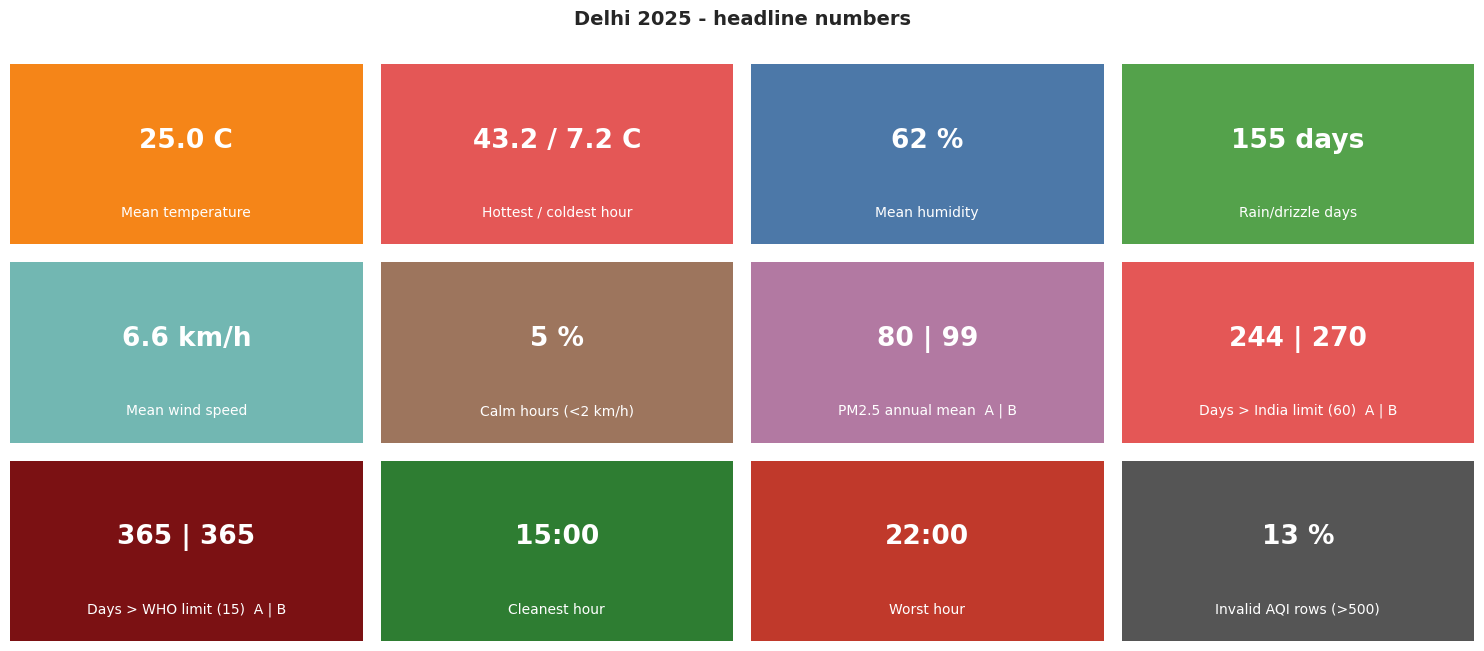

In [ ]:
A = daily_z[daily_z.zone == "Zone A"]; B = daily_z[daily_z.zone == "Zone B"]
tiles = [
    ("Mean temperature", f"{T.mean():.1f} C", "#f58518"),
    ("Hottest / coldest hour", f"{T.max():.1f} / {T.min():.1f} C", "#e45756"),
    ("Mean humidity", f"{city.humidity.mean():.0f} %", "#4c78a8"),
    ("Rain/drizzle days", f"{rain_days} days", "#54a24b"),
    ("Mean wind speed", f"{city.windspeed_kph.mean():.1f} km/h", "#72b7b2"),
    ("Calm hours (<2 km/h)", f"{(city.windspeed_kph < 2).mean()*100:.0f} %", "#9d755d"),
    ("PM2.5 annual mean  A | B", f"{hz[hz.zone=='Zone A'].pm2_5.mean():.0f} | {hz[hz.zone=='Zone B'].pm2_5.mean():.0f}", "#b279a2"),
    ("Days > India limit (60)  A | B", f"{(A.pm2_5>60).sum()} | {(B.pm2_5>60).sum()}", "#e45756"),
    ("Days > WHO limit (15)  A | B", f"{(A.pm2_5>15).sum()} | {(B.pm2_5>15).sum()}", "#7b1113"),
    ("Cleanest hour", f"{city.groupby('hour').pm2_5.mean().idxmin()}:00", "#2e7d32"),
    ("Worst hour", f"{city.groupby('hour').pm2_5.mean().idxmax()}:00", "#c0392b"),
    ("Invalid AQI rows (>500)", f"{(df.aqi_index>500).mean()*100:.0f} %", "#555555"),
]
fig, axes = plt.subplots(3, 4, figsize=(15, 6.5))
for ax, (name, val, col) in zip(axes.ravel(), tiles):
    ax.set_facecolor(col); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(False)
    ax.text(0.5, 0.58, val, ha="center", va="center", fontsize=19, color="white", fontweight="bold", transform=ax.transAxes)
    ax.text(0.5, 0.18, name, ha="center", va="center", fontsize=10, color="white", transform=ax.transAxes)
show(fig, "01_kpi_tiles", "Delhi 2025 - headline numbers")

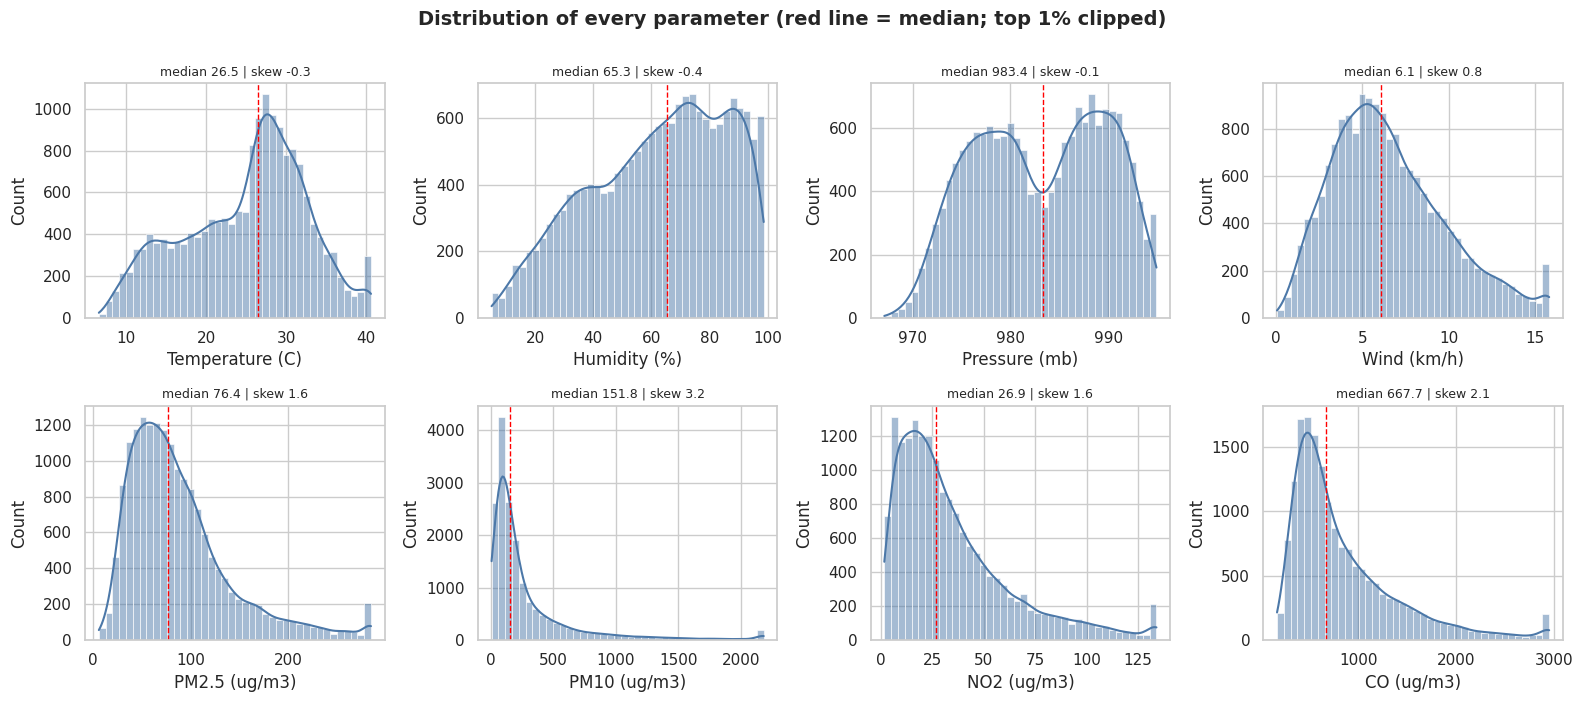

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), num):
    x = hz[c].clip(upper=hz[c].quantile(.99))
    sns.histplot(x, bins=40, kde=True, ax=ax, color="#4c78a8")
    ax.axvline(hz[c].median(), color="red", ls="--", lw=1)
    ax.set_xlabel(lab[c]); ax.set_title(f"median {hz[c].median():.1f} | skew {stats.skew(hz[c]):.1f}", fontsize=9)
show(fig, "02_distributions", "Distribution of every parameter (red line = median; top 1% clipped)")

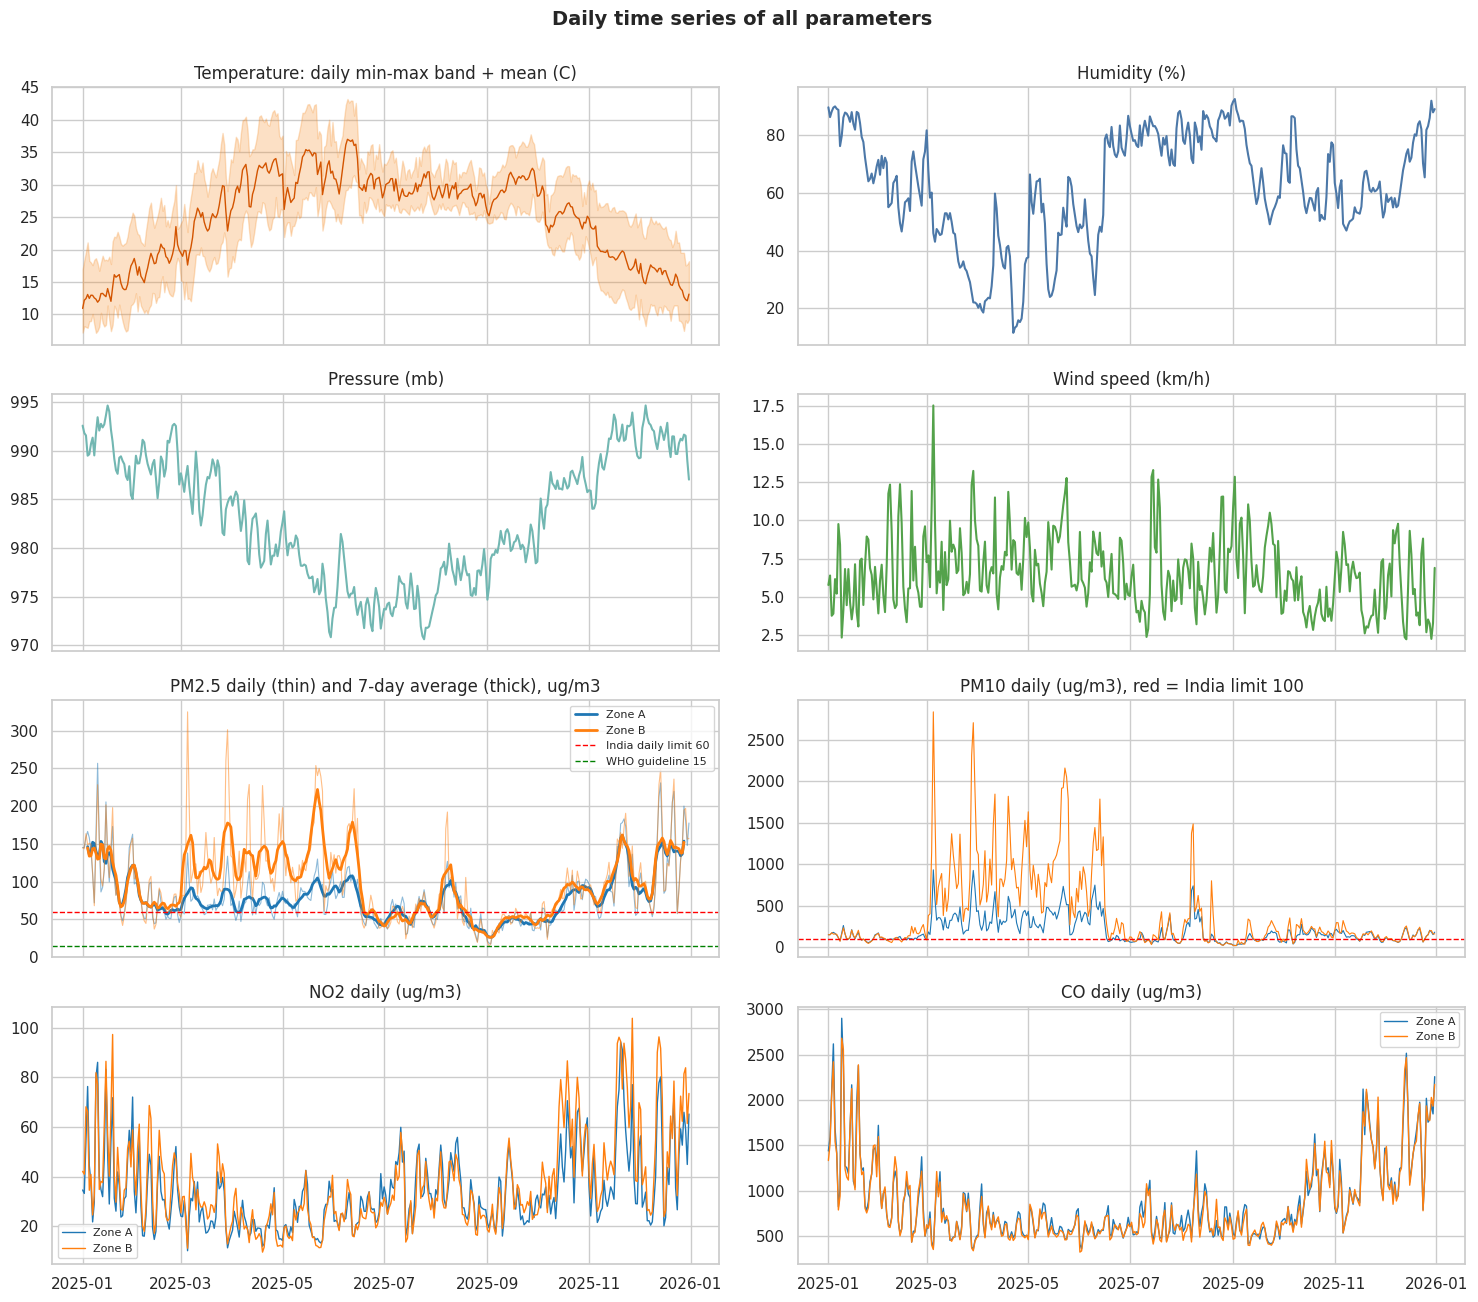

In [ ]:
fig, axes = plt.subplots(4, 2, figsize=(15, 13), sharex=True)
ax = axes[0, 0]
ax.fill_between(dmax.index, dmin, dmax, alpha=.25, color="#f58518")
ax.plot(daily_c.temp_c, color="#d35400", lw=1); ax.set_title("Temperature: daily min-max band + mean (C)")
axes[0, 1].plot(daily_c.humidity, color="#4c78a8"); axes[0, 1].set_title("Humidity (%)")
axes[1, 0].plot(daily_c.pressure_mb, color="#72b7b2"); axes[1, 0].set_title("Pressure (mb)")
axes[1, 1].plot(daily_c.windspeed_kph, color="#54a24b"); axes[1, 1].set_title("Wind speed (km/h)")
for z, col in zip(["Zone A", "Zone B"], ["#1f77b4", "#ff7f0e"]):
    g = daily_z[daily_z.zone == z].set_index("date")
    axes[2, 0].plot(g.pm2_5, color=col, lw=.8, alpha=.5)
    axes[2, 0].plot(g.pm2_5.rolling(7, center=True).mean(), color=col, lw=2, label=z)
    axes[2, 1].plot(g.pm10, color=col, lw=.8, label=z)
    axes[3, 0].plot(g.no2, color=col, lw=1, label=z)
    axes[3, 1].plot(g.co, color=col, lw=1, label=z)
axes[2, 0].axhline(60, color="red", ls="--", lw=1, label="India daily limit 60")
axes[2, 0].axhline(15, color="green", ls="--", lw=1, label="WHO guideline 15")
axes[2, 0].set_title("PM2.5 daily (thin) and 7-day average (thick), ug/m3"); axes[2, 0].legend(fontsize=8)
axes[2, 1].axhline(100, color="red", ls="--", lw=1); axes[2, 1].set_title("PM10 daily (ug/m3), red = India limit 100")
axes[3, 0].set_title("NO2 daily (ug/m3)"); axes[3, 1].set_title("CO daily (ug/m3)")
for a in axes[3]: a.legend(fontsize=8)
show(fig, "03_time_series", "Daily time series of all parameters")

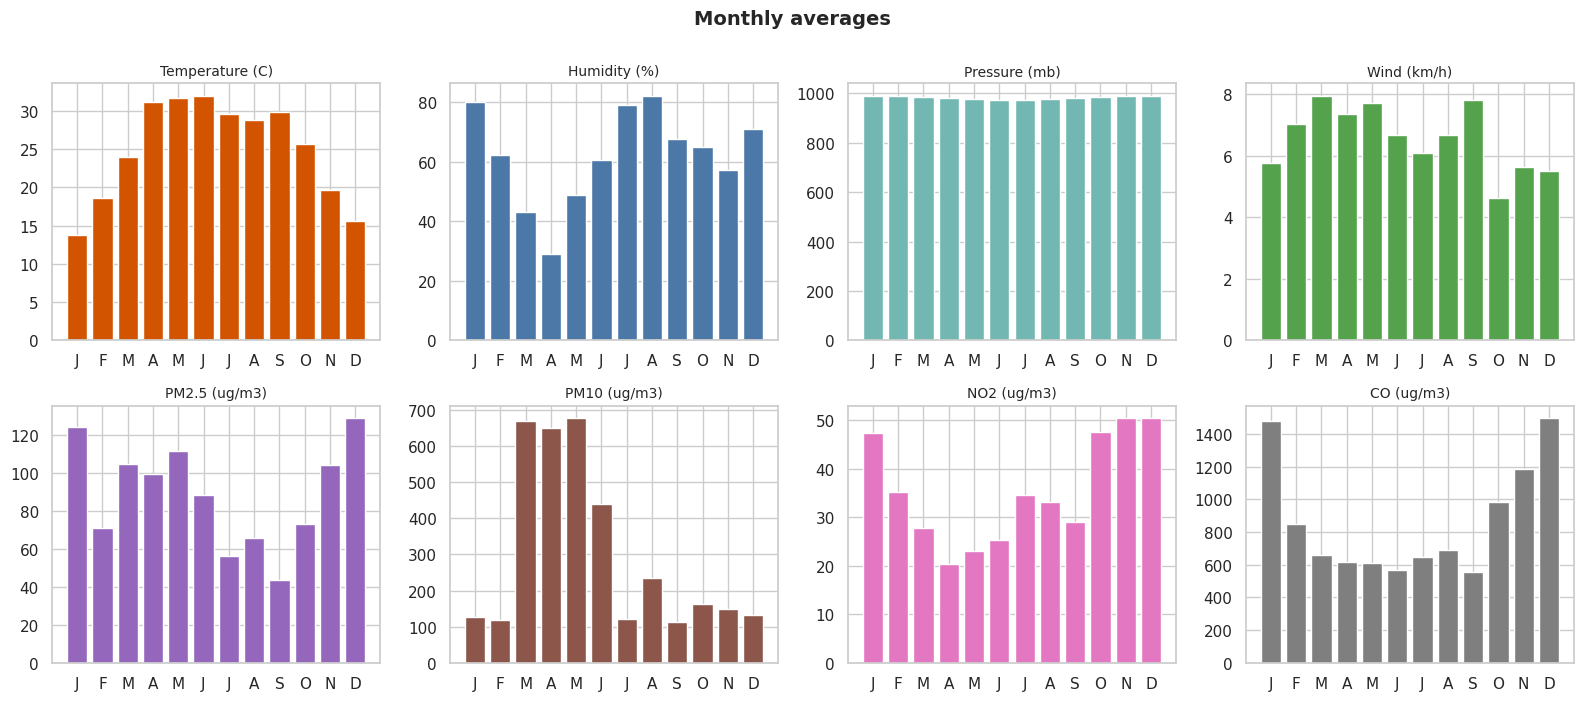

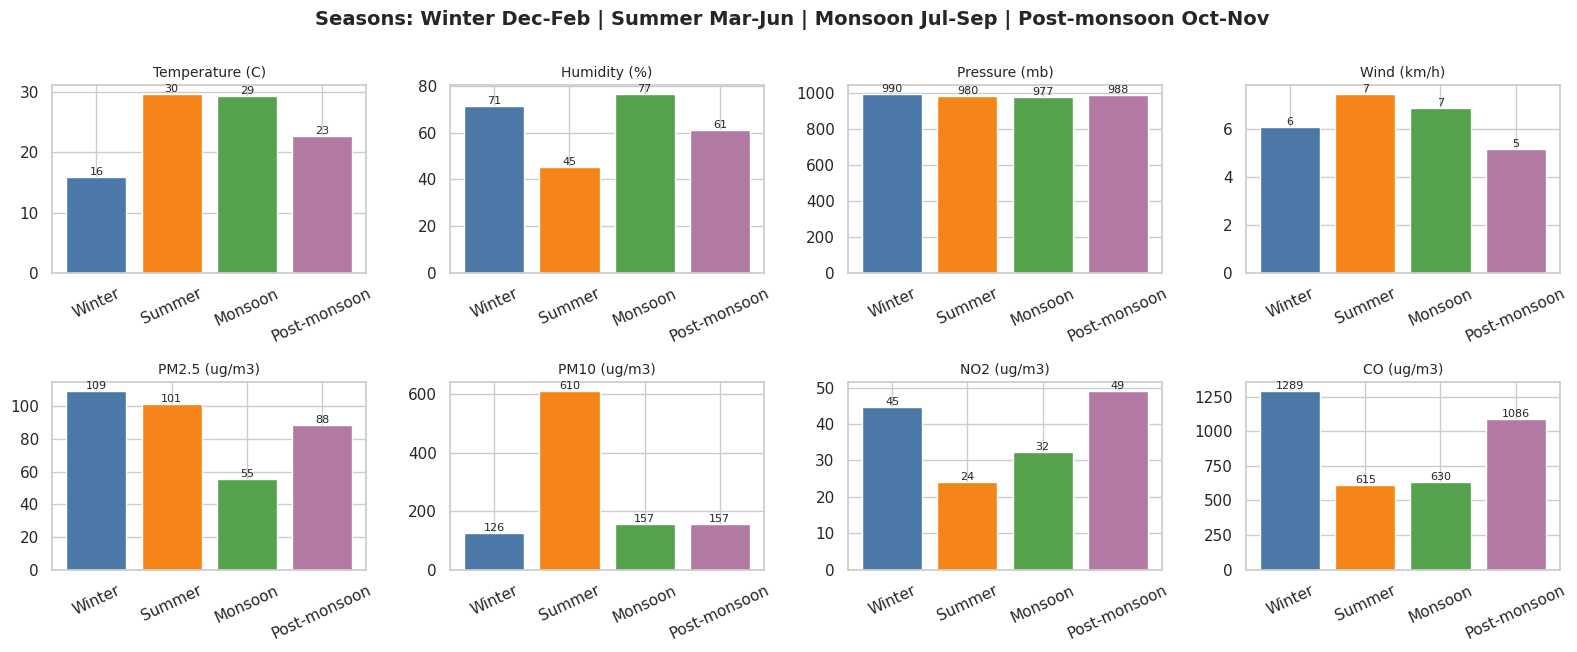

In [ ]:
colors = ["#d35400","#4c78a8","#72b7b2","#54a24b","#9467bd","#8c564b","#e377c2","#7f7f7f"]
mon = city.groupby("month")[num].mean()
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c, col in zip(axes.ravel(), num, colors):
    ax.bar(range(1, 13), mon[c], color=col); ax.set_xticks(range(1, 13)); ax.set_xticklabels([m[0] for m in MON])
    ax.set_title(lab[c], fontsize=10)
show(fig, "04_monthly_means", "Monthly averages")

seas = city.groupby("season")[num].mean().loc[SEASONS]
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for ax, c in zip(axes.ravel(), num):
    ax.bar(SEASONS, seas[c], color=[SEASON_COL[s] for s in SEASONS]); ax.tick_params(axis="x", rotation=25)
    ax.set_title(lab[c], fontsize=10)
    for i, v in enumerate(seas[c]): ax.text(i, v, f"{v:.0f}", ha="center", va="bottom", fontsize=8)
show(fig, "05_seasonal_means", "Seasons: Winter Dec-Feb | Summer Mar-Jun | Monsoon Jul-Sep | Post-monsoon Oct-Nov")

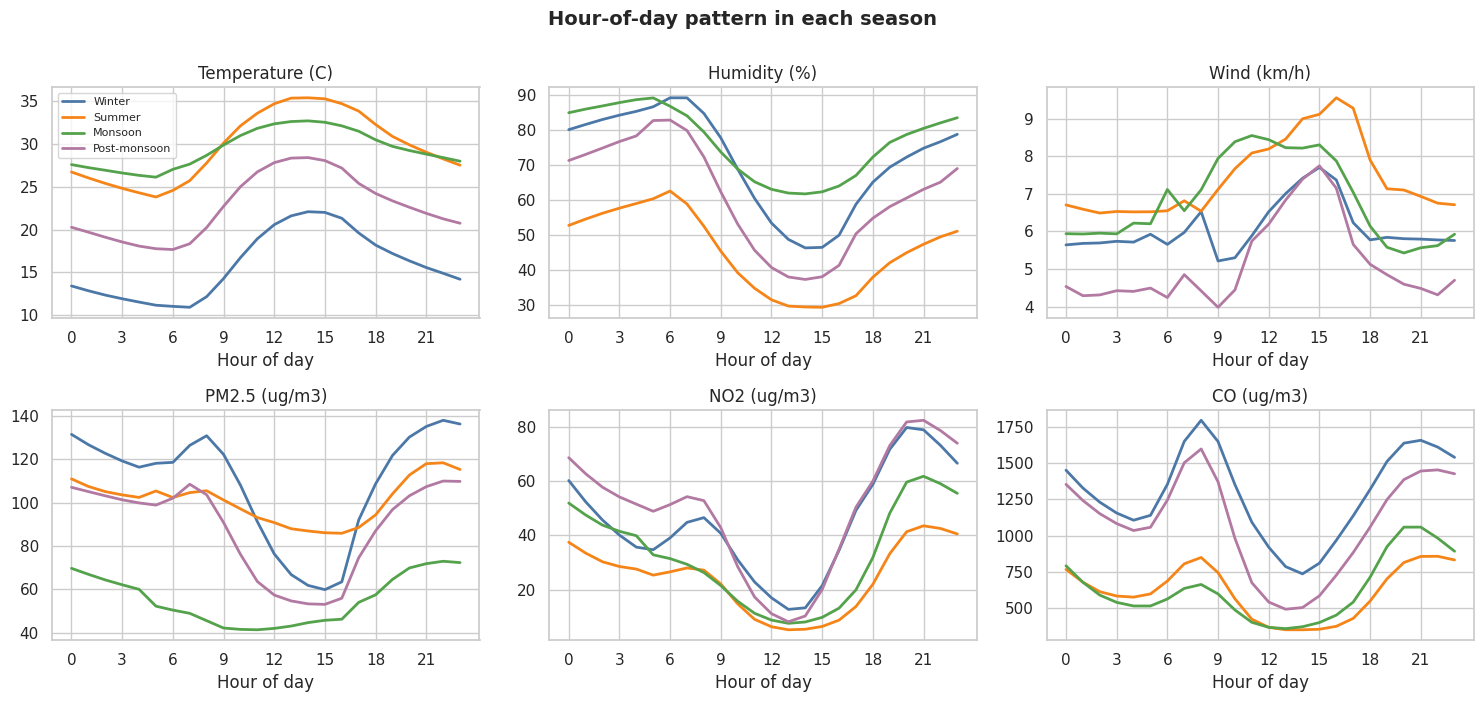

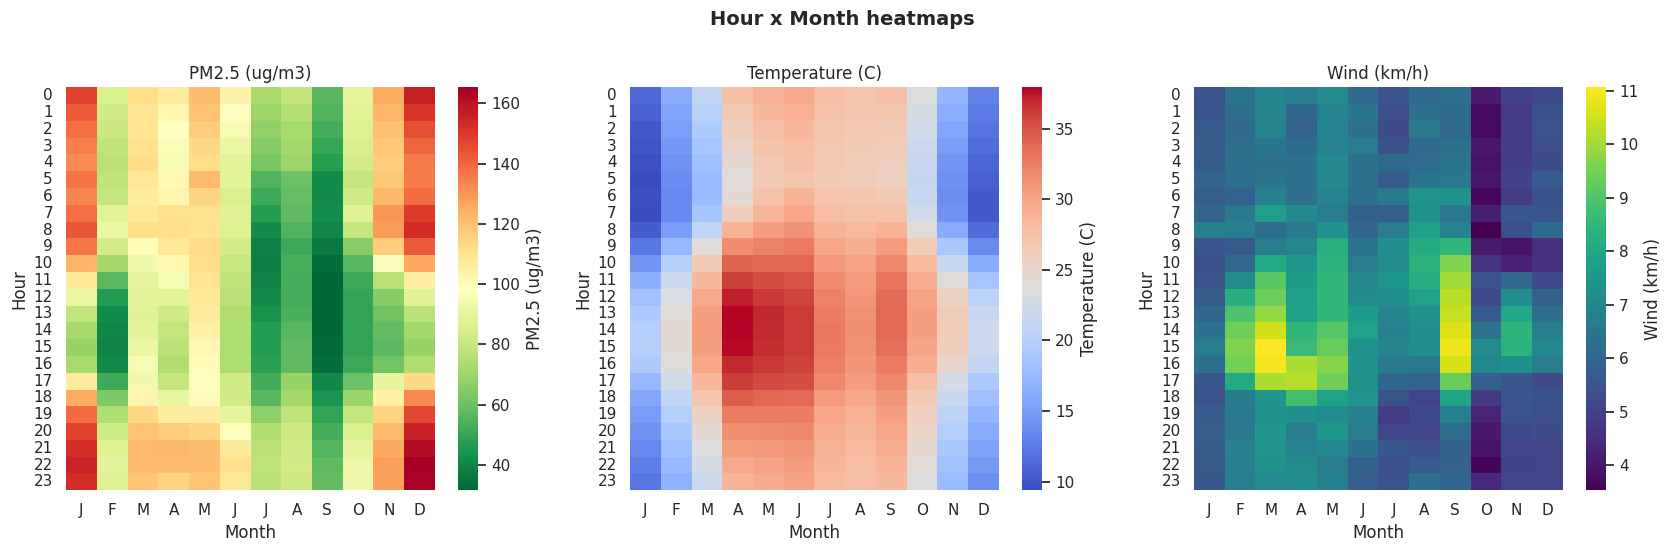

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.ravel(), ["temp_c","humidity","windspeed_kph","pm2_5","no2","co"]):
    for s in SEASONS:
        ax.plot(city[city.season == s].groupby("hour")[c].mean(), label=s, color=SEASON_COL[s], lw=2)
    ax.set_xlabel("Hour of day"); ax.set_title(lab[c]); ax.set_xticks(range(0, 24, 3))
axes[0, 0].legend(fontsize=8)
show(fig, "06_daily_cycle_by_season", "Hour-of-day pattern in each season")

fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
for ax, (c, cm, t) in zip(axes, [("pm2_5","RdYlGn_r","PM2.5 (ug/m3)"), ("temp_c","coolwarm","Temperature (C)"),
                                 ("windspeed_kph","viridis","Wind (km/h)")]):
    pv = city.pivot_table(index="hour", columns="month", values=c, aggfunc="mean")
    sns.heatmap(pv, cmap=cm, ax=ax, cbar_kws={"label": t}, xticklabels=[m[0] for m in MON])
    ax.set_title(t); ax.set_xlabel("Month"); ax.set_ylabel("Hour")
show(fig, "07_hour_month_heatmaps", "Hour x Month heatmaps")

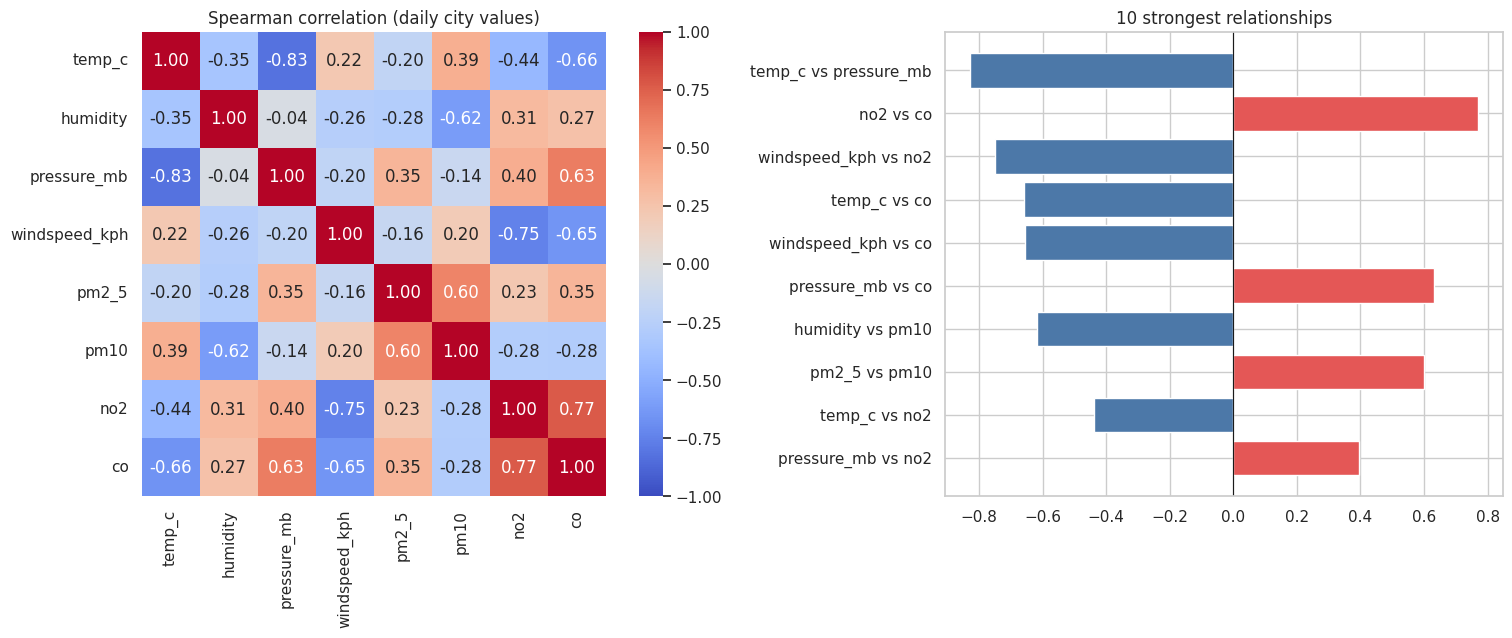

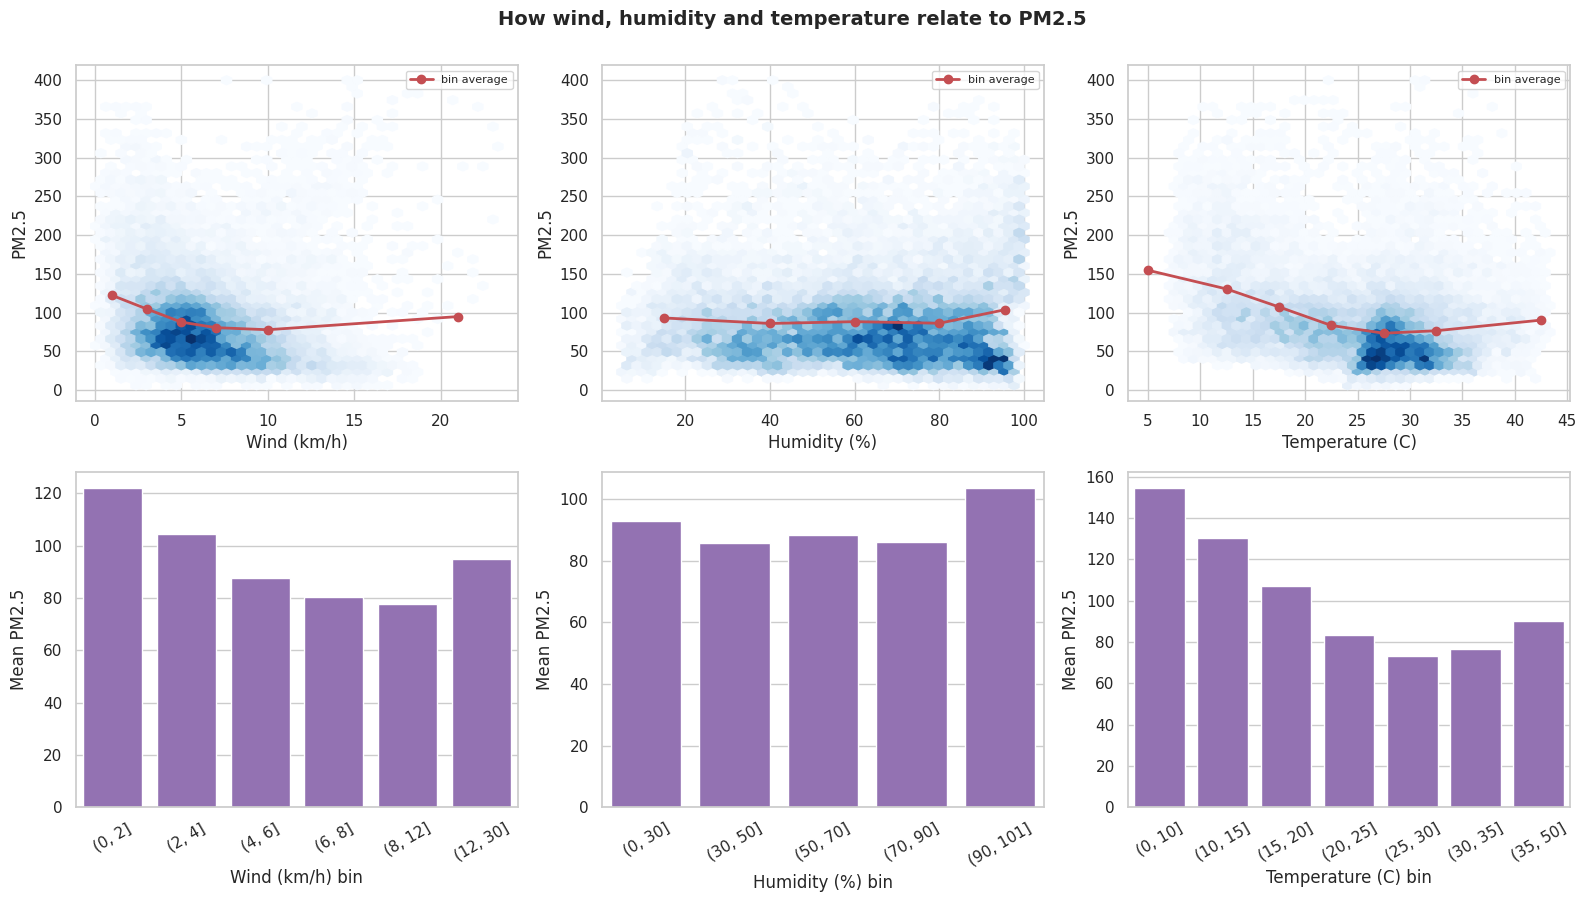

In [ ]:
sp = daily_c[num].corr(method="spearman")
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.2, 1]})
sns.heatmap(sp, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0], square=True)
axes[0].set_title("Spearman correlation (daily city values)")
pairs = sp.where(np.triu(np.ones(sp.shape), 1).astype(bool)).stack().sort_values(key=abs, ascending=False).head(10)
axes[1].barh([f"{a} vs {b}" for a, b in pairs.index][::-1], pairs.values[::-1],
             color=["#e45756" if v > 0 else "#4c78a8" for v in pairs.values[::-1]])
axes[1].set_title("10 strongest relationships"); axes[1].axvline(0, color="k", lw=.8)
show(fig, "08_correlations")

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
bins = {"windspeed_kph":[0,2,4,6,8,12,30], "humidity":[0,30,50,70,90,101], "temp_c":[0,10,15,20,25,30,35,50]}
for j, (c, b) in enumerate(bins.items()):
    d = hz.assign(bin=pd.cut(hz[c], b))
    axes[0, j].hexbin(hz[c], hz.pm2_5.clip(upper=400), gridsize=40, cmap="Blues", mincnt=1)
    m = d.groupby("bin").pm2_5.mean(); mid = [i.mid for i in m.index]
    axes[0, j].plot(mid, m.values, "r-o", lw=2, label="bin average")
    axes[0, j].set_xlabel(lab[c]); axes[0, j].set_ylabel("PM2.5"); axes[0, j].legend(fontsize=8)
    sns.barplot(x=[str(i) for i in m.index], y=m.values, ax=axes[1, j], color="#9467bd")
    axes[1, j].tick_params(axis="x", rotation=30); axes[1, j].set_ylabel("Mean PM2.5"); axes[1, j].set_xlabel(f"{lab[c]} bin")
show(fig, "09_weather_vs_pm25", "How wind, humidity and temperature relate to PM2.5")

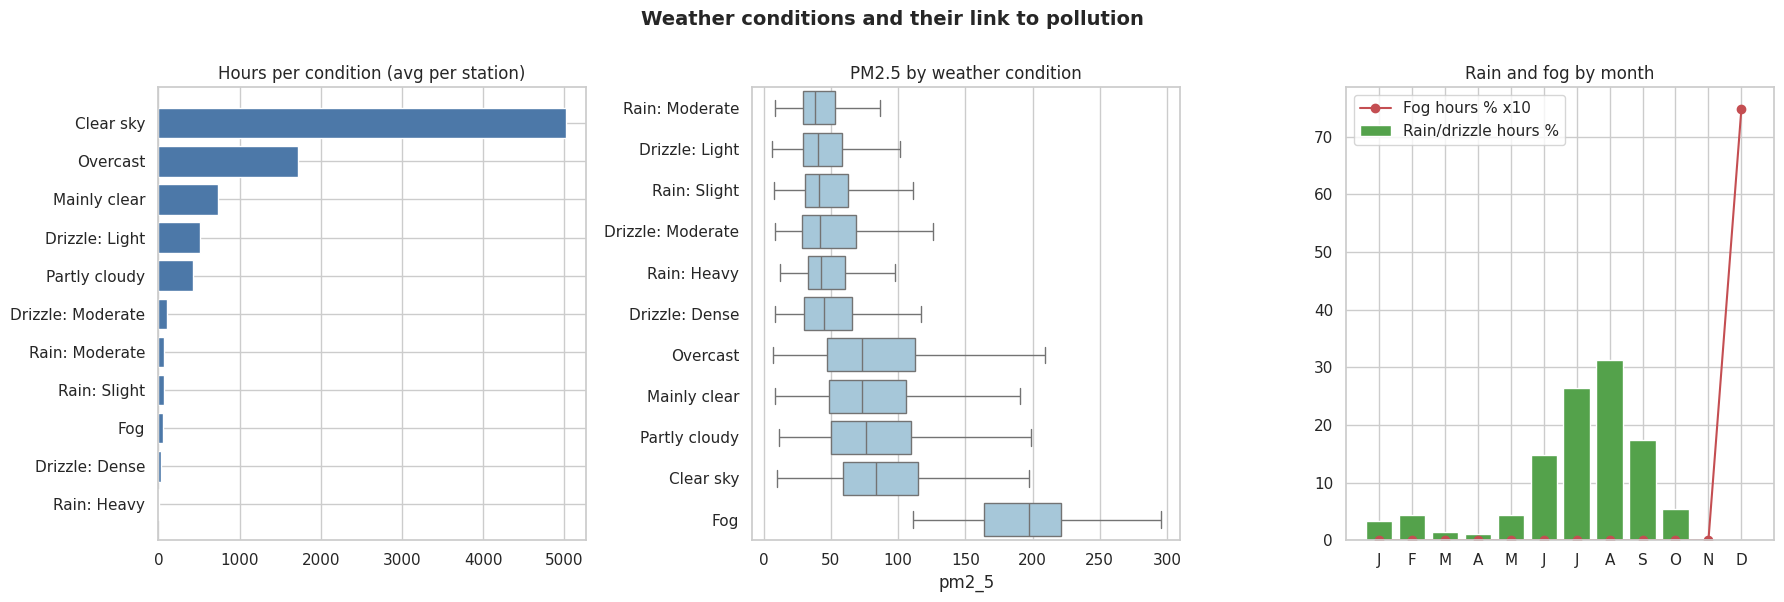

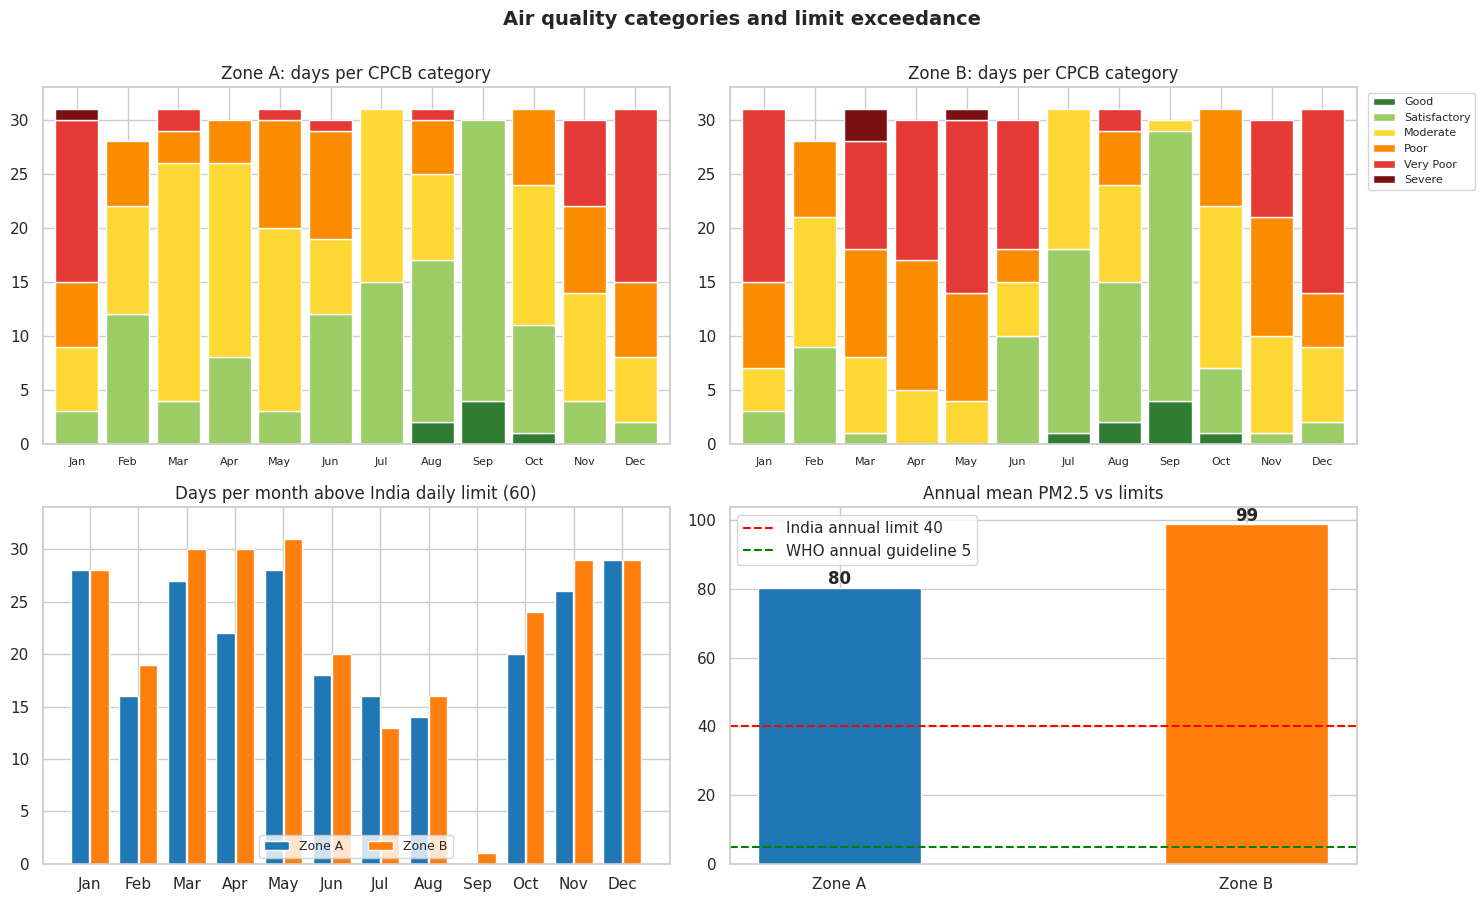

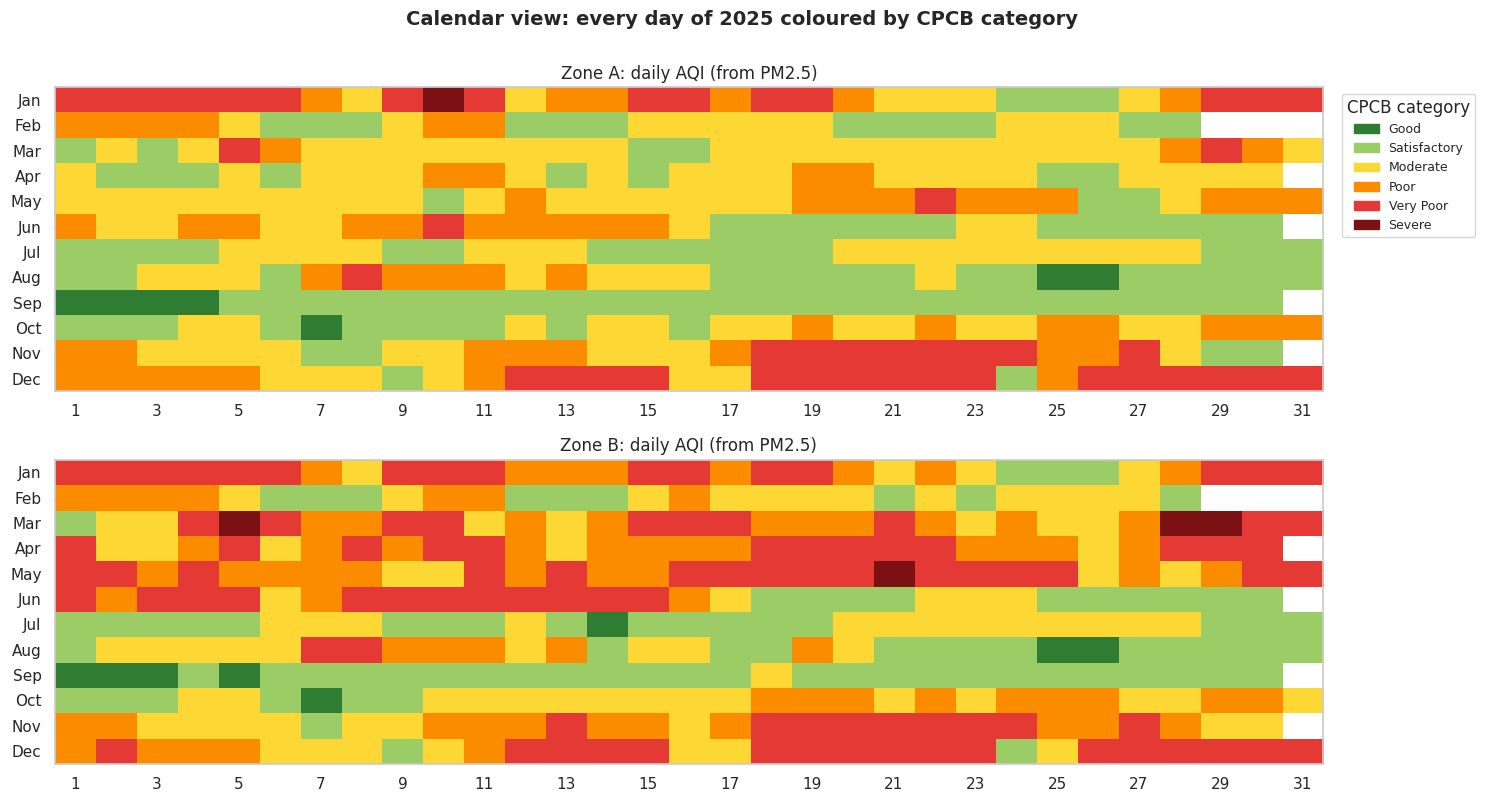

In [ ]:
cond = df.condition_text.value_counts()
order = df.groupby("condition_text").pm2_5.median().sort_values().index
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].barh(cond.index[::-1], cond.values[::-1] / 6, color="#4c78a8"); axes[0].set_title("Hours per condition (avg per station)")
sns.boxplot(data=df, y="condition_text", x="pm2_5", order=order, ax=axes[1], showfliers=False, color="#9ecae1")
axes[1].set_title("PM2.5 by weather condition"); axes[1].set_ylabel("")
w = df.assign(wet=wet, fog=df.condition_text == "Fog", month=df.datetime.dt.month).groupby("month")[["wet","fog"]].mean() * 100
axes[2].bar(range(1, 13), w.wet, color="#54a24b", label="Rain/drizzle hours %")
axes[2].plot(range(1, 13), w.fog * 10, "ro-", label="Fog hours % x10")
axes[2].set_xticks(range(1, 13)); axes[2].set_xticklabels([m[0] for m in MON]); axes[2].legend(); axes[2].set_title("Rain and fog by month")
show(fig, "10_weather_conditions", "Weather conditions and their link to pollution")

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for z, ax in zip(["Zone A", "Zone B"], [axes[0, 0], axes[0, 1]]):
    g = daily_z[daily_z.zone == z]
    t = g.groupby(["month","cat"], observed=False).size().unstack(fill_value=0)[CAT_L]
    t.plot(kind="bar", stacked=True, color=CAT_C, ax=ax, width=.85, legend=False)
    ax.set_title(f"{z}: days per CPCB category"); ax.set_xticklabels(MON, rotation=0, fontsize=8)
    ax.set_xlabel(""); ax.set_ylim(0, 33)
axes[0, 1].legend(CAT_L, bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
for z, off, colr in zip(["Zone A", "Zone B"], [-.2, .2], ["#1f77b4", "#ff7f0e"]):
    g = daily_z[daily_z.zone == z]
    cnt = g[g.pm2_5 > 60].groupby("month").size().reindex(range(1, 13), fill_value=0)
    axes[1, 0].bar(np.arange(12) + off, cnt.values, .38, label=z, color=colr)
axes[1, 0].set_xticks(range(12)); axes[1, 0].set_xticklabels(MON)
axes[1, 0].set_title("Days per month above India daily limit (60)")
axes[1, 0].legend(loc="lower center", ncol=2, fontsize=9); axes[1, 0].set_ylim(0, 34)
ann = [hz[hz.zone == z].pm2_5.mean() for z in ["Zone A", "Zone B"]]
axes[1, 1].bar(["Zone A", "Zone B"], ann, color=["#1f77b4", "#ff7f0e"], width=.4)
axes[1, 1].axhline(40, color="red", ls="--", label="India annual limit 40")
axes[1, 1].axhline(5, color="green", ls="--", label="WHO annual guideline 5")
for i, v in enumerate(ann): axes[1, 1].text(i, v + 1, f"{v:.0f}", ha="center", fontweight="bold")
axes[1, 1].legend(); axes[1, 1].set_title("Annual mean PM2.5 vs limits")
show(fig, "11_compliance_categories", "Air quality categories and limit exceedance")

cmap = ListedColormap(CAT_C); norm = BoundaryNorm([0, 50, 100, 200, 300, 400, 500], cmap.N)
fig, axes = plt.subplots(2, 1, figsize=(15, 8))
for ax, z in zip(axes, ["Zone A", "Zone B"]):
    g = daily_z[daily_z.zone == z]
    grid = np.full((12, 31), np.nan)
    for _, r in g.iterrows(): grid[r.date.month - 1, r.date.day - 1] = r.aqi
    ax.imshow(grid, cmap=cmap, norm=norm, aspect="auto")
    ax.set_yticks(range(12)); ax.set_yticklabels(MON)
    ax.set_xticks(range(0, 31, 2)); ax.set_xticklabels(range(1, 32, 2))
    ax.set_title(f"{z}: daily AQI (from PM2.5)"); ax.grid(False)
axes[0].legend(handles=[Patch(color=c, label=l) for c, l in zip(CAT_C, CAT_L)],
               bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=9, title="CPCB category")
show(fig, "12_aqi_calendar", "Calendar view: every day of 2025 coloured by CPCB category")

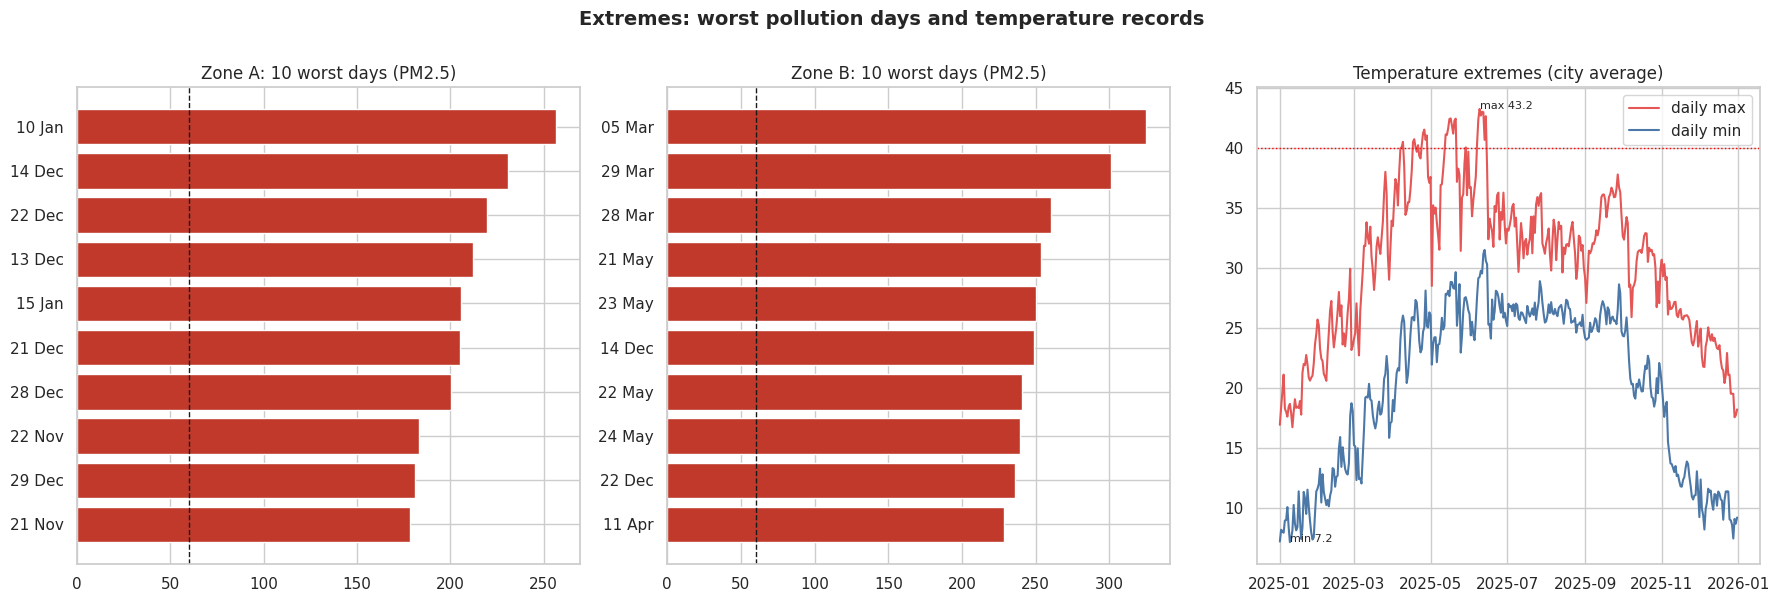

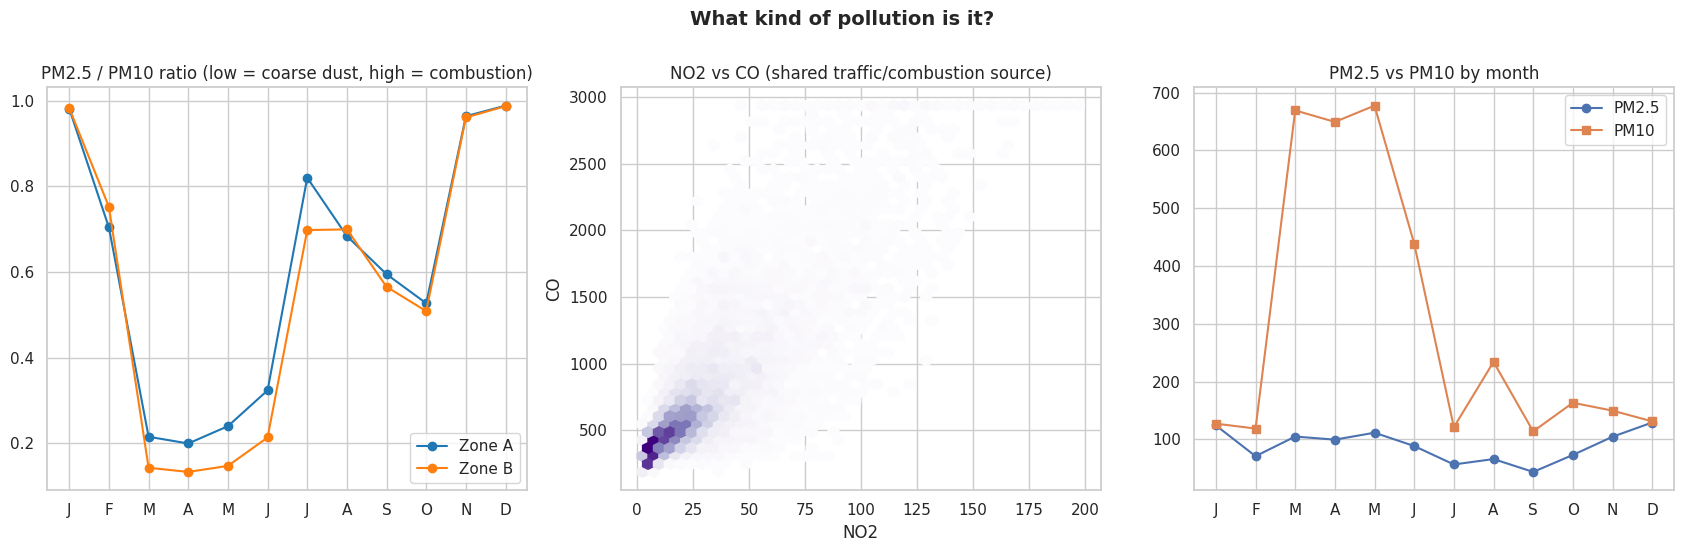

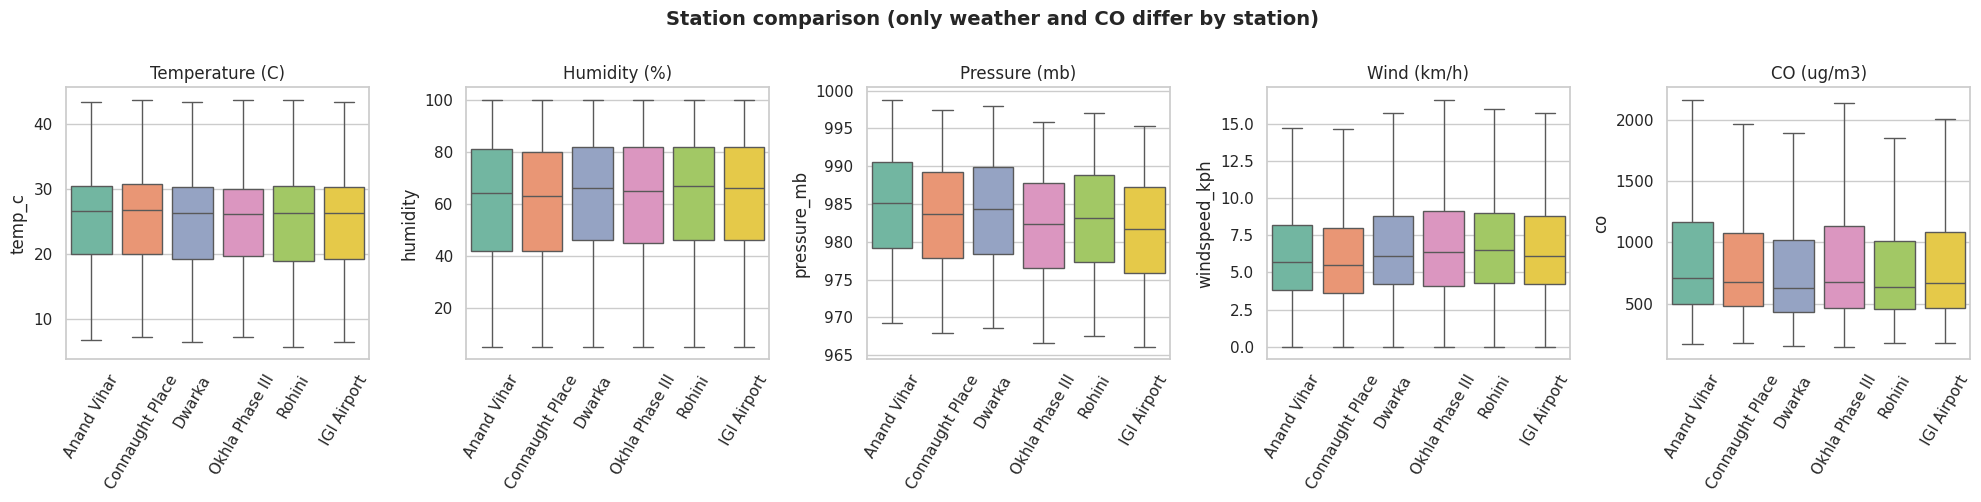

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, z in zip(axes[:2], ["Zone A", "Zone B"]):
    top = daily_z[daily_z.zone == z].nlargest(10, "pm2_5")
    ax.barh(top.date.dt.strftime("%d %b")[::-1], top.pm2_5[::-1], color="#c0392b")
    ax.set_title(f"{z}: 10 worst days (PM2.5)"); ax.axvline(60, color="k", ls="--", lw=1)
axes[2].plot(dmax.index, dmax, color="#e45756", label="daily max")
axes[2].plot(dmin.index, dmin, color="#4c78a8", label="daily min")
axes[2].axhline(40, color="red", ls=":", lw=1); axes[2].legend(); axes[2].set_title("Temperature extremes (city average)")
axes[2].annotate(f"max {dmax.max():.1f}", (dmax.idxmax(), dmax.max()), fontsize=8)
axes[2].annotate(f"min {dmin.min():.1f}", (dmin.idxmin(), dmin.min()), fontsize=8)
show(fig, "13_extremes", "Extremes: worst pollution days and temperature records")

fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
for z, col in zip(["Zone A", "Zone B"], ["#1f77b4", "#ff7f0e"]):
    h = hz[hz.zone == z]
    axes[0].plot(range(1, 13), (h.pm2_5 / h.pm10).groupby(h.month).median(), "o-", color=col, label=z)
axes[0].set_xticks(range(1, 13)); axes[0].set_xticklabels([m[0] for m in MON]); axes[0].legend()
axes[0].set_title("PM2.5 / PM10 ratio (low = coarse dust, high = combustion)")
axes[1].hexbin(city.no2, city.co.clip(upper=city.co.quantile(.99)), gridsize=40, cmap="Purples", mincnt=1)
axes[1].set_xlabel("NO2"); axes[1].set_ylabel("CO"); axes[1].set_title("NO2 vs CO (shared traffic/combustion source)")
rk = hz.groupby("month")[["pm2_5","pm10"]].mean()
axes[2].plot(range(1, 13), rk.pm2_5, "o-", label="PM2.5"); axes[2].plot(range(1, 13), rk.pm10, "s-", label="PM10")
axes[2].set_xticks(range(1, 13)); axes[2].set_xticklabels([m[0] for m in MON]); axes[2].legend(); axes[2].set_title("PM2.5 vs PM10 by month")
show(fig, "14_pollutant_character", "What kind of pollution is it?")

fig, axes = plt.subplots(1, 5, figsize=(20, 5))
for ax, c in zip(axes, ["temp_c","humidity","pressure_mb","windspeed_kph","co"]):
    sns.boxplot(data=df, x="location", y=c, ax=ax, showfliers=False, palette="Set2")
    ax.tick_params(axis="x", rotation=60); ax.set_title(lab[c]); ax.set_xlabel("")
show(fig, "15_stations_weather", "Station comparison (only weather and CO differ by station)")

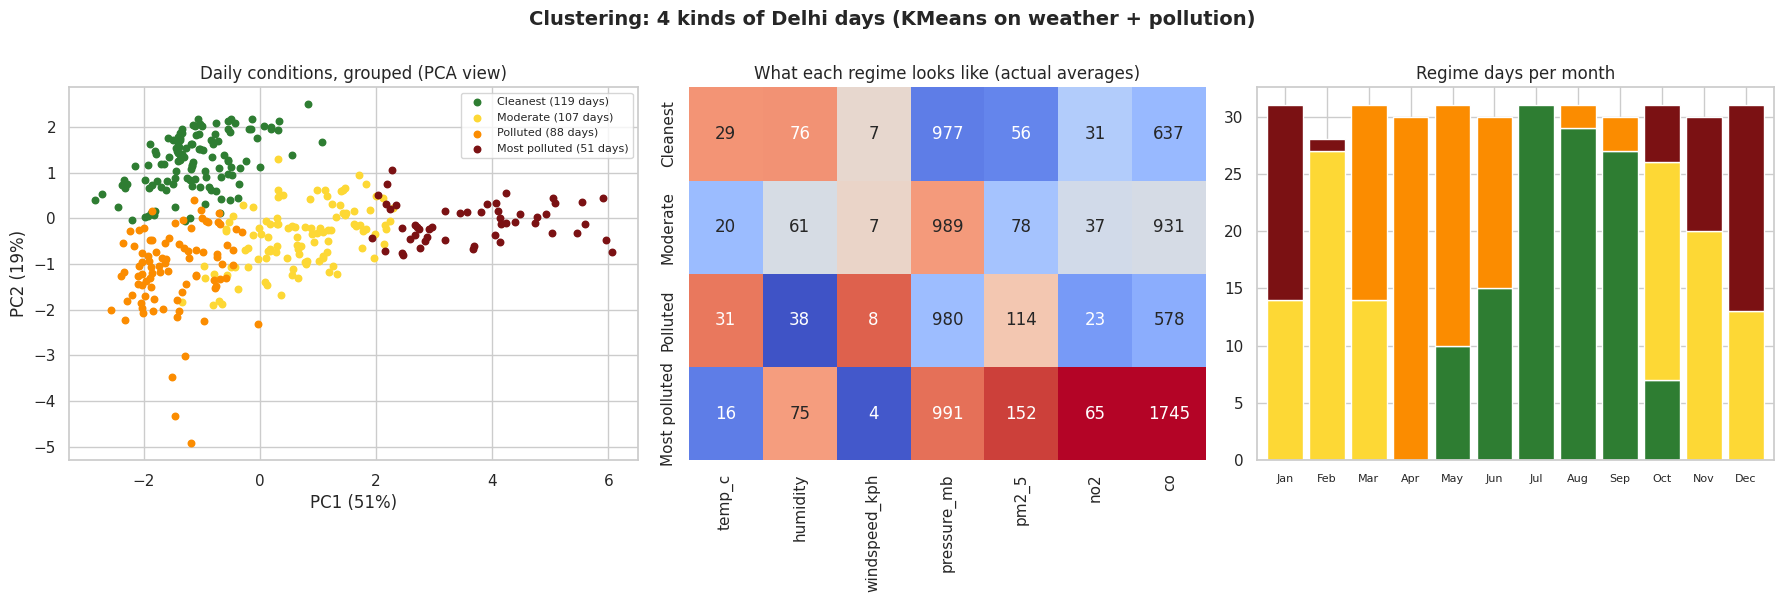

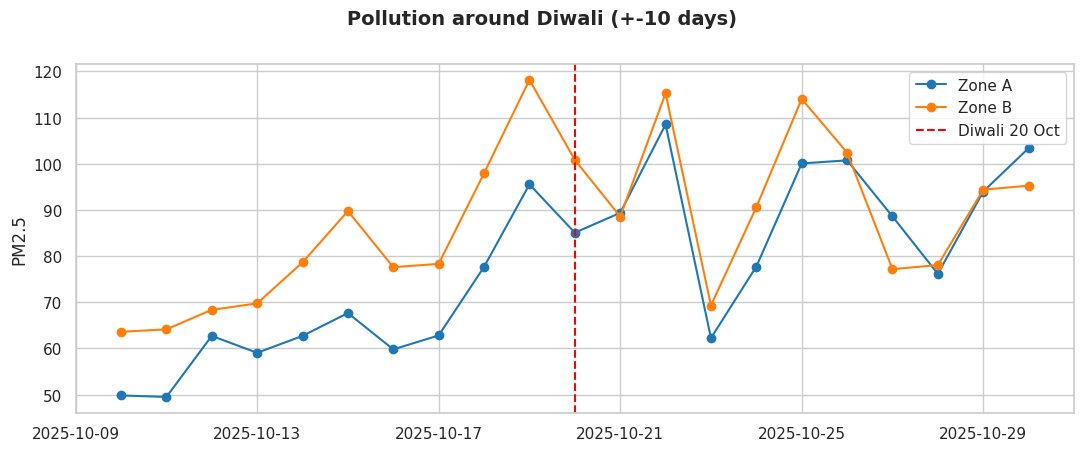

In [ ]:
feat = ["temp_c","humidity","windspeed_kph","pressure_mb","pm2_5","no2","co"]
Zs = StandardScaler().fit_transform(daily_c[feat])
km = KMeans(n_clusters=4, n_init=20, random_state=0).fit(Zs)
daily_c["regime"] = km.labels_
prof = daily_c.groupby("regime")[feat].mean()
order_r = prof.pm2_5.sort_values().index.tolist()
names = dict(zip(order_r, ["Cleanest", "Moderate", "Polluted", "Most polluted"]))
daily_c["regime_name"] = daily_c.regime.map(names)
p2 = PCA(n_components=2, random_state=0).fit(Zs); xy = p2.transform(Zs)
pal = dict(zip(["Cleanest","Moderate","Polluted","Most polluted"], ["#2e7d32","#fdd835","#fb8c00","#7b1113"]))

fig, axes = plt.subplots(1, 3, figsize=(18, 6), gridspec_kw={"width_ratios": [1.1, 1, 1]})
for n, c in pal.items():
    m = (daily_c.regime_name == n).values
    axes[0].scatter(xy[m, 0], xy[m, 1], c=c, label=f"{n} ({m.sum()} days)", s=22)
axes[0].legend(fontsize=8)
axes[0].set_xlabel(f"PC1 ({p2.explained_variance_ratio_[0]*100:.0f}%)"); axes[0].set_ylabel(f"PC2 ({p2.explained_variance_ratio_[1]*100:.0f}%)")
axes[0].set_title("Daily conditions, grouped (PCA view)")
zprof = (prof - prof.mean()) / prof.std(); zprof.index = [names[i] for i in zprof.index]
sns.heatmap(zprof.loc[list(pal)], annot=prof.rename(index=names).loc[list(pal)].round(0), fmt=".0f",
            cmap="coolwarm", center=0, ax=axes[1], cbar=False)
axes[1].set_title("What each regime looks like (actual averages)")
ct = pd.crosstab(daily_c.month, daily_c.regime_name)[list(pal)]; ct.index = MON
ct.plot(kind="bar", stacked=True, color=list(pal.values()), ax=axes[2], legend=False, width=.85)
axes[2].set_title("Regime days per month"); axes[2].tick_params(axis="x", rotation=0, labelsize=8)
show(fig, "16_weather_pollution_regimes", "Clustering: 4 kinds of Delhi days (KMeans on weather + pollution)")

DIW = pd.Timestamp("2025-10-20")
fig, ax = plt.subplots(figsize=(11, 4.5))
for z, col in zip(["Zone A", "Zone B"], ["#1f77b4", "#ff7f0e"]):
    g = daily_z[(daily_z.zone == z) & (daily_z.date.between(DIW - pd.Timedelta(days=10), DIW + pd.Timedelta(days=10)))]
    ax.plot(g.date, g.pm2_5, "o-", color=col, label=z)
ax.axvline(DIW, color="red", ls="--", label="Diwali 20 Oct"); ax.legend(); ax.set_ylabel("PM2.5")
show(fig, "17_diwali_window", "Pollution around Diwali (+-10 days)")

In [ ]:
!zip -r -q results.zip charts key_parameters.csv
from google.colab import files
files.download("results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>